# **STUDENT PASS/FAIL CLASSIFICATION MODEL**

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# Create a new dataset

In [88]:
# data = {
#     "Study_Hours": [
#         1, 2, 2, 3, 3, 4, 4, 5, 5, 6,
#         6, 7, 7, 8, 8, 9, 9, 10, 3, 4
#     ],

#     "Attendance": [
#         45, 50, 55, 52, 60, 58, 65, 62, 68, 70,
#         75, 72, 80, 78, 85, 82, 90, 95, 45, 88
#     ],

#     "Previous_Marks": [
#         28, 32, 35, 38, 42, 40, 48, 50, 52, 55,
#         58, 62, 65, 68, 72, 75, 80, 85, 90, 70
#     ],

#     "Result": [
#         "Fail", "Fail", "Fail", "Fail", "Fail",
#         "Fail", "Fail", "Fail", "Pass", "Fail",
#         "Pass", "Pass", "Pass", "Pass", "Pass",
#         "Pass", "Pass", "Pass", "Fail", "Pass"
#     ]
# }

# df = pd.DataFrame(data)

# # Convert categorical values into numerical values
# df["Result"] = df["Result"].map({"Fail": 0, "Pass": 1})

# print(df)


In [89]:
# Generate small Dataset
data = {
    "Study_Hours": [1,2,2,3,3,4,4,5,5,6,
                    6,7,7,8,8,9,9,10,3,6],

    "Attendence": [45,50,55,52,60,58,65,62,70,68,
                   75,72,80,78,85,82,90,95,48,88],

    "Previous_Marks": [28,32,35,38,42,40,48,50,52,55,
                       58,62,65,68,72,75,80,88,30,70],

    "Result": ["Fail","Fail","Fail","Fail","Fail",
               "Fail","Fail","Fail","Pass","Fail",
               "Pass","Pass","Pass","Pass","Pass",
               "Pass","Pass","Pass","Fail","Pass"]
}

df = pd.DataFrame(data)

df["Result"] = df["Result"].map({"Fail": 0, "Pass": 1})

print(df)


    Study_Hours  Attendence  Previous_Marks  Result
0             1          45              28       0
1             2          50              32       0
2             2          55              35       0
3             3          52              38       0
4             3          60              42       0
5             4          58              40       0
6             4          65              48       0
7             5          62              50       0
8             5          70              52       1
9             6          68              55       0
10            6          75              58       1
11            7          72              62       1
12            7          80              65       1
13            8          78              68       1
14            8          85              72       1
15            9          82              75       1
16            9          90              80       1
17           10          95              88       1
18          

**understand the dataset**

In [90]:
# btw useless code for this type of dataset
print("print five rows")
print(df.head())

print("shape(row,columns):",df.shape)
print("column names:",df.columns)
print("data types and non-null counts:")
df.info()

print("statisical summary:")
print(df.describe())

print five rows
   Study_Hours  Attendence  Previous_Marks  Result
0            1          45              28       0
1            2          50              32       0
2            2          55              35       0
3            3          52              38       0
4            3          60              42       0
shape(row,columns): (20, 4)
column names: Index(['Study_Hours', 'Attendence', 'Previous_Marks', 'Result'], dtype='object')
data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Study_Hours     20 non-null     int64
 1   Attendence      20 non-null     int64
 2   Previous_Marks  20 non-null     int64
 3   Result          20 non-null     int64
dtypes: int64(4)
memory usage: 772.0 bytes
statisical summary:
       Study_Hours  Attendence  Previous_Marks     Result
count    20.000000   20.000000       20.00

In [91]:
print("Missing values: ")
print(df.isnull().sum())

print("Duplicate rows: ")
print(df.duplicated().sum())

print("Class distribution: ")
print(df["Result"].value_counts())

Missing values: 
Study_Hours       0
Attendence        0
Previous_Marks    0
Result            0
dtype: int64
Duplicate rows: 
0
Class distribution: 
Result
0    10
1    10
Name: count, dtype: int64


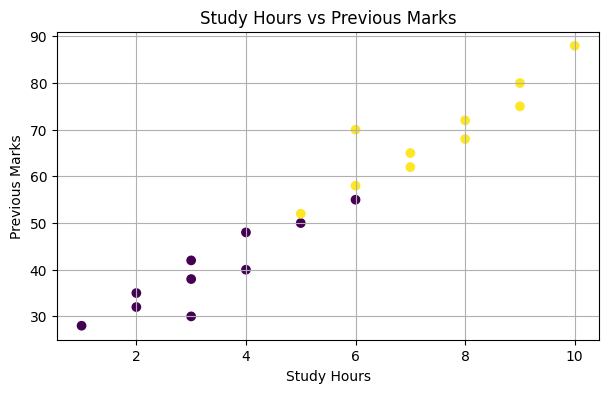

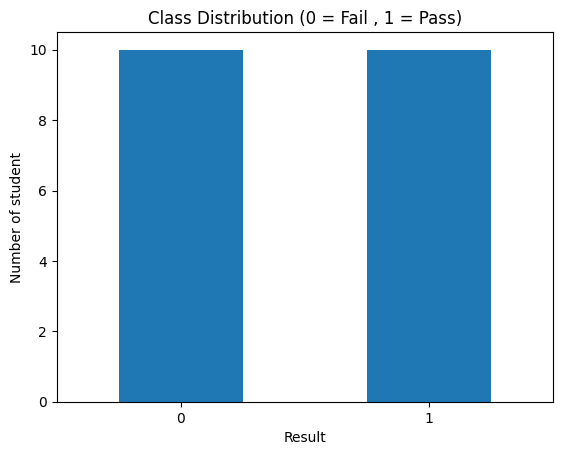

In [92]:
plt.figure(figsize=(7, 4))
plt.scatter(df['Study_Hours'],df['Previous_Marks'],c=df['Result'])
plt.xlabel('Study Hours')
plt.ylabel('Previous Marks')
plt.title('Study Hours vs Previous Marks')
plt.grid(True)
plt.show()

print("\n\n\n")

df['Result'].value_counts().sort_index().plot(kind='bar',
                                              rot=0,
                                              title='Class Distribution (0 = Fail , 1 = Pass)'
)
plt.xlabel('Result')
plt.ylabel('Number of student')
plt.show()
#

In [93]:
x = df[["Study_Hours","Attendence","Previous_Marks"]]
y = df["Result"]

print("Feature (X): \n",x.head())
print("Target (Y): \n",y.tail())

Feature (X): 
    Study_Hours  Attendence  Previous_Marks
0            1          45              28
1            2          50              32
2            2          55              35
3            3          52              38
4            3          60              42
Target (Y): 
 15    1
16    1
17    1
18    0
19    1
Name: Result, dtype: int64


In [94]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=42,stratify=y)
print("Training records:",len(x_train))
print("Testing records:",len(x_test))

Training records: 15
Testing records: 5


In [95]:
model = LogisticRegression()
model.fit(x_train,y_train)

print(model.predict(x_test))
print(x_test)
print(y_test)

[0 0 1 1 0]
    Study_Hours  Attendence  Previous_Marks
4             3          60              42
7             5          62              50
16            9          90              80
13            8          78              68
3             3          52              38
4     0
7     0
16    1
13    1
3     0
Name: Result, dtype: int64


In [96]:
y_pred = model.predict(x_test)

comparison = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
print(comparison)

    Actual  Predicted
4        0          0
7        0          0
16       1          1
13       1          1
3        0          0


In [97]:
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
print("Rows = Actual, Columns = Predicted")
print(cm)

Rows = Actual, Columns = Predicted
[[3 0]
 [0 2]]


In [102]:
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred,zero_division=0)
f1 = f1_score(y_test, y_pred,zero_division=0)

print("Accuracy: ", round(accuracy,3))
print("Precision: ", round(precision,3))
print("Recall: ", round(recall,3))
print("F1 Score: ", round(f1,3))

print("\nDeatiled Classification report: ")
print(classification_report(y_test, y_pred,
                            labels=[0,1],
                            target_names=["Fail","Pass"],
                            zero_division=0
))


Accuracy:  1.0
Precision:  1.0
Recall:  1.0
F1 Score:  1.0

Deatiled Classification report: 
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         3
        Pass       1.00      1.00      1.00         2

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [105]:
probabilities = model.predict_proba(x_test)
print("Columns are ordered as classes: ",model.classes_)
print("Probabilities: \n",probabilities)

Columns are ordered as classes:  [0 1]
Probabilities: 
 [[9.99564997e-01 4.35002634e-04]
 [9.98014453e-01 1.98554657e-03]
 [7.86250054e-09 9.99999992e-01]
 [3.67690984e-04 9.99632309e-01]
 [9.99999702e-01 2.97621706e-07]]


In [118]:
new_student = pd.DataFrame({
    "Study_Hours" : [8],
    "Attendence"  : [70],
    "Previous_Marks" : [80]
})

predicted_class = model.predict(new_student)[0]
predicted_prob = model.predict_proba(new_student)[0]

if predicted_class == 1:
  print("Predicted result: Pass")
else:
  print("Predicted result: Fail")

print("Class order: ",model.classes_)
print("Probabilities: ",predicted_prob)
print("Probabilities: ",round(predicted_prob[0],5),round(predicted_prob[1],5))

Predicted result: Pass
Class order:  [0 1]
Probabilities:  [0.39040581 0.60959419]
Probabilities:  0.39041 0.60959
